**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Italo Javier Contreras Pérez
*   MATRÍCULA: A01841252

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [696]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.


In [697]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [698]:
loan_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/MNA/1er trimestre/Ciencia y analitica de datos/semana 4/personal_loan.csv')

display(loan_df)

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes
5035,5035,56,32,58,95064,1,1.8,3.0,241,0,No,No,Yes,0


* Haz que la columna `ID` sea el índice del dataframe.


In [699]:
loan_df.set_index('ID', inplace=True)
display(loan_df)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes


* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [700]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


8 columnas son numericas y 5 columnas son de texto

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.

In [701]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.


In [702]:
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [703]:
loan_df = loan_df[loan_df['Age'] <= 100]

In [704]:
display(loan_df)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes


Se eliminaron esos 3 registros ya que tienen edades imposibles

* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.

In [705]:
loan_df[loan_df['Experience'] < 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


In [706]:
loan_df = loan_df[loan_df['Experience'] >= 0]
loan_df.head(5)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


Se eliminaron los registros que tienen años de experiencia negativa ya que esto no existe

In [707]:
loan_df[loan_df['Family'] < 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [708]:
loan_df = loan_df[loan_df['Family'] > 0]

Se eliminaron los registros que tienen familia negativa ya que esto no es posible

In [709]:
print(loan_df['Education'].value_counts().sort_index())
loan_df[~loan_df['Education'].isin([1, 2, 3])]

Education
1.0    2098
2.0    1393
3.0    1487
7.3       1
Name: count, dtype: int64


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


In [710]:
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]

Se elimina un registro ya que la variable Education es ordinal entera

In [711]:
loan_df[loan_df['ZIP Code'] < 10000]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [712]:
loan_df = loan_df[loan_df['ZIP Code'] >= 10000]

Se elimina el ZIP Code que tiene solo 4 digitos

* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

Al final se eliminaron 60 registros lo cual vendria a ser el 1.2% del total

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.


In [713]:
loan_df.describe(exclude='number').T

,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628


In [714]:
txt_cols = loan_df.select_dtypes(exclude='number').columns.tolist()
for column in txt_cols:
    print(loan_df[column].value_counts())
    print(' ')

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64
 
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64
 
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64
 
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64
 
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64
 


* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [715]:
mapa_binario = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

for column in bin_cols:
    loan_df[column] = loan_df[column].map(mapa_binario).astype('int64')



In [716]:
txt_cols = loan_df.select_dtypes(exclude='number').columns.tolist()
for column in txt_cols:
    print(loan_df[column].value_counts())
    print(' ')

Veo que ya fueron transformadas correctamente de su tipo de dato original

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.

In [717]:
print(loan_df.duplicated().sum())

36


* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [718]:
loan_df = loan_df.drop_duplicates()

loan_df = loan_df.reset_index(drop=True)
loan_df.head(5)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1.0,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2.0,0,0,0,0,0,1


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`


In [719]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')

loan_df['Education'] = pd.Categorical(loan_df['Education'].astype(int), categories=[1, 2, 3], ordered=True)

bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
loan_df[bin_cols] = loan_df[bin_cols].astype('category')

loan_df.dtypes

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [720]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

print(num_cols)
print(cat_cols)

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.


In [721]:
desc = loan_df[num_cols].describe().T
desc['skew'] = loan_df[num_cols].skew()
desc['kurtosis'] = loan_df[num_cols].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.


-Age tiene skew -0.02 y curtosis -1.16 por lo tanto es aproximadamente simetrica y platicurtica


-Income tiene skew 0.84 y curtosis -0.05 por lo tanto tiene una ligera asimetria hacia la derecha y es casi mesocúrtica

-Mortgage tiene skew 2.10 y curtosis 4.76 por lo tanto es asimétrica hacia la derecha y leptocúrtica


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.

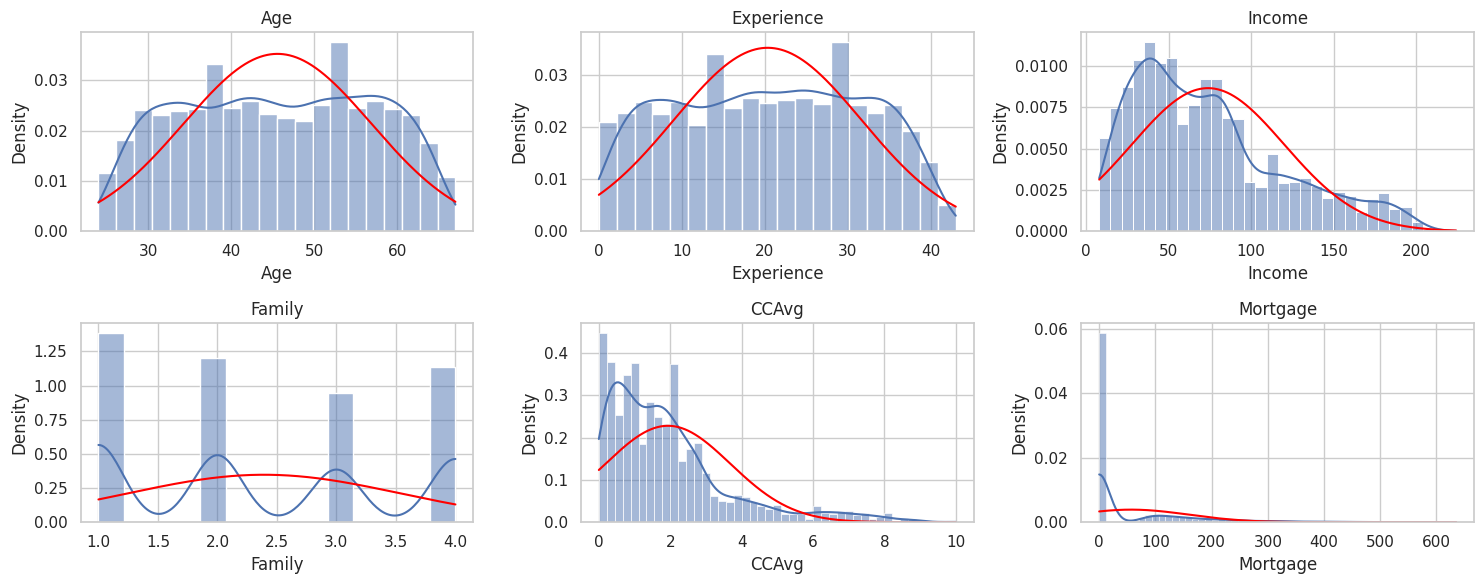

In [722]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
    sns.histplot(x=loan_df[col], stat='density', kde=True, ax=ax)
    # curva normal de referencia
    x_vals = np.linspace(loan_df[col].min(), loan_df[col].max(), 1000)
    ax.plot(x_vals, norm.pdf(x_vals, loan_df[col].mean(), loan_df[col].std()), color='red')
    ax.set_title(col)

plt.tight_layout()
plt.show()

Vemos que las graficas de la 3 variables (Age, Income y Mortgage) si coinciden de acuerdo a la descripcion que habiamos hecho en la pregunta anterior viendo el skew y la curtosis

* Para cada variable, crea un gráfico de boxplot individual que incluya la media.

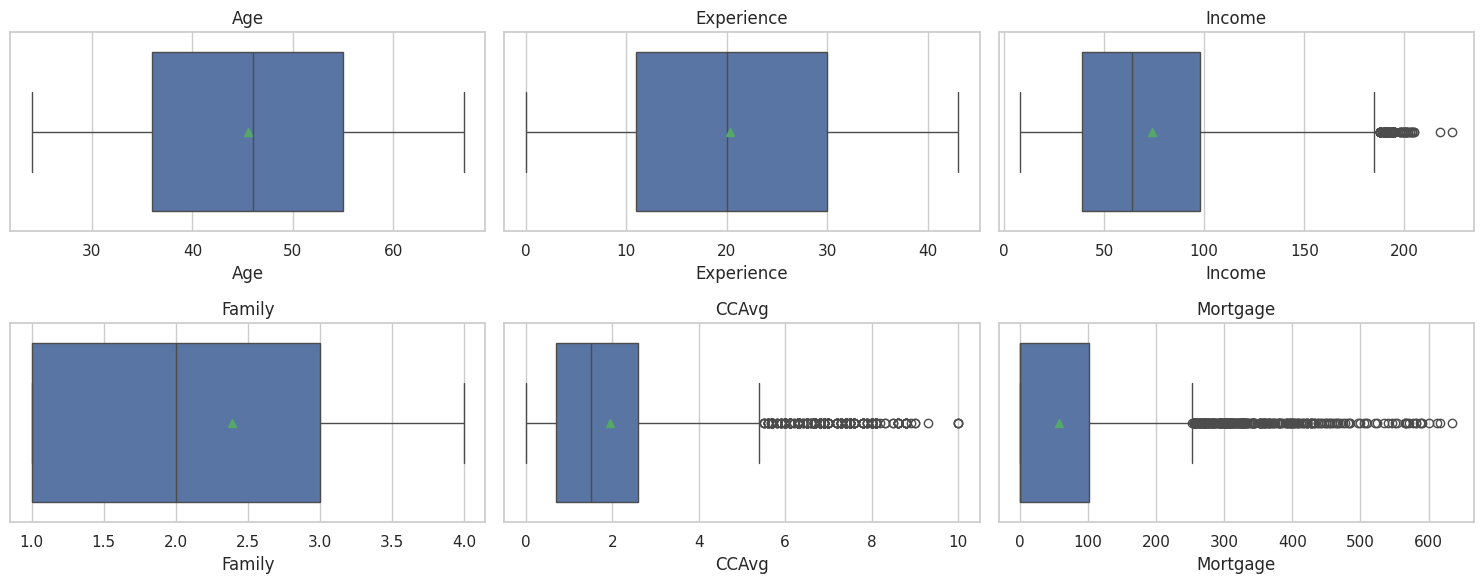

In [723]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
    sns.boxplot(x=loan_df[col], ax=ax, showmeans=True)
    ax.set_title(col)

plt.tight_layout()
plt.show()

* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

In [724]:
pd.DataFrame({'media': loan_df[num_cols].mean(), 'mediana': loan_df[num_cols].median()})

,media,mediana
Age,45.560210,46.0
Experience,20.335357,20.0
Income,73.826553,64.0
Family,2.391621,2.0
CCAvg,1.935855,1.5
Mortgage,56.663631,0.0


-Age y Experience tienen una media y mediana practicamente igual esto quiere decir que son simetricas

-En Income, CCAvg y Mortgage la media es mayor que la mediana. Tienen sesgo positivo

-Family tiene muy poco sesgo

8. Obtén las estadísticas descriptivas de las variables categóricas.


In [725]:
loan_df[cat_cols].describe().T

,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

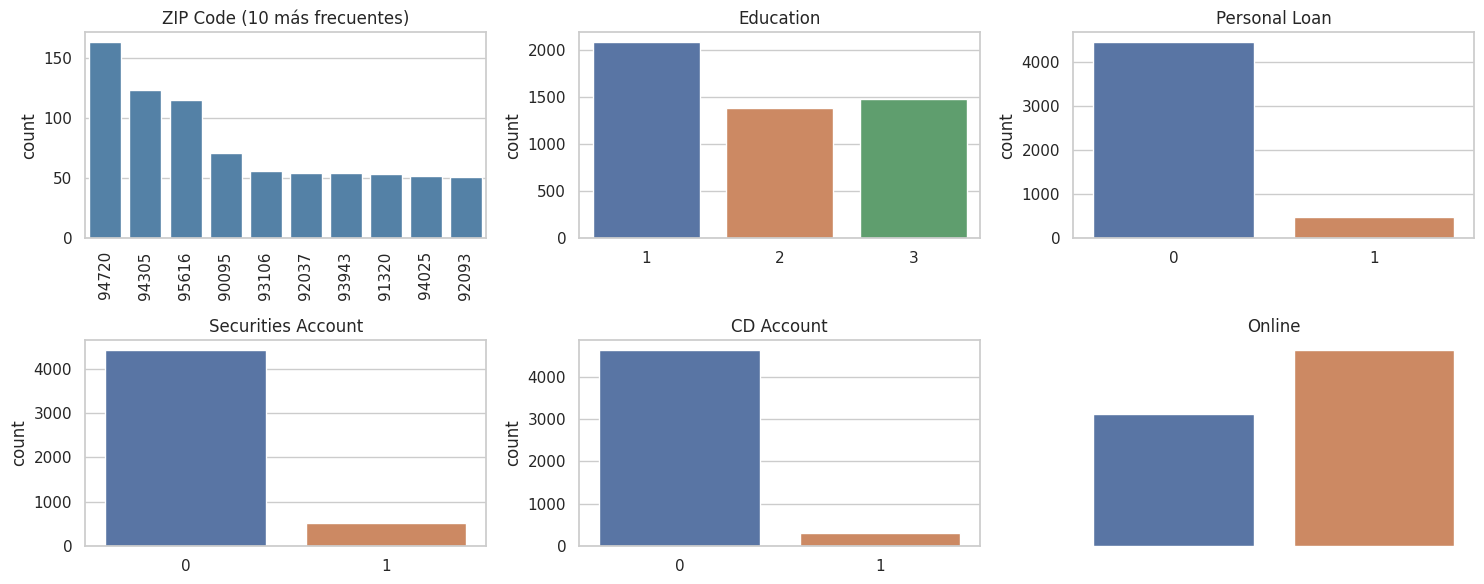

In [726]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()

for col, ax in zip(cat_cols, axes):
    if col == 'ZIP Code': #Zip tiene alta cardinalidad
        top10 = loan_df[col].value_counts().head(10).index
        sns.countplot(x=loan_df[col], order=top10, ax=ax, color='steelblue')
        ax.set(title='ZIP Code (10 más frecuentes)')
        ax.tick_params(axis='x', rotation=90)
    else:
        sns.countplot(x=loan_df[col], hue=loan_df[col], legend=False, ax=ax)
        ax.set(title=f'{col}')
    ax.set(xlabel=None)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.


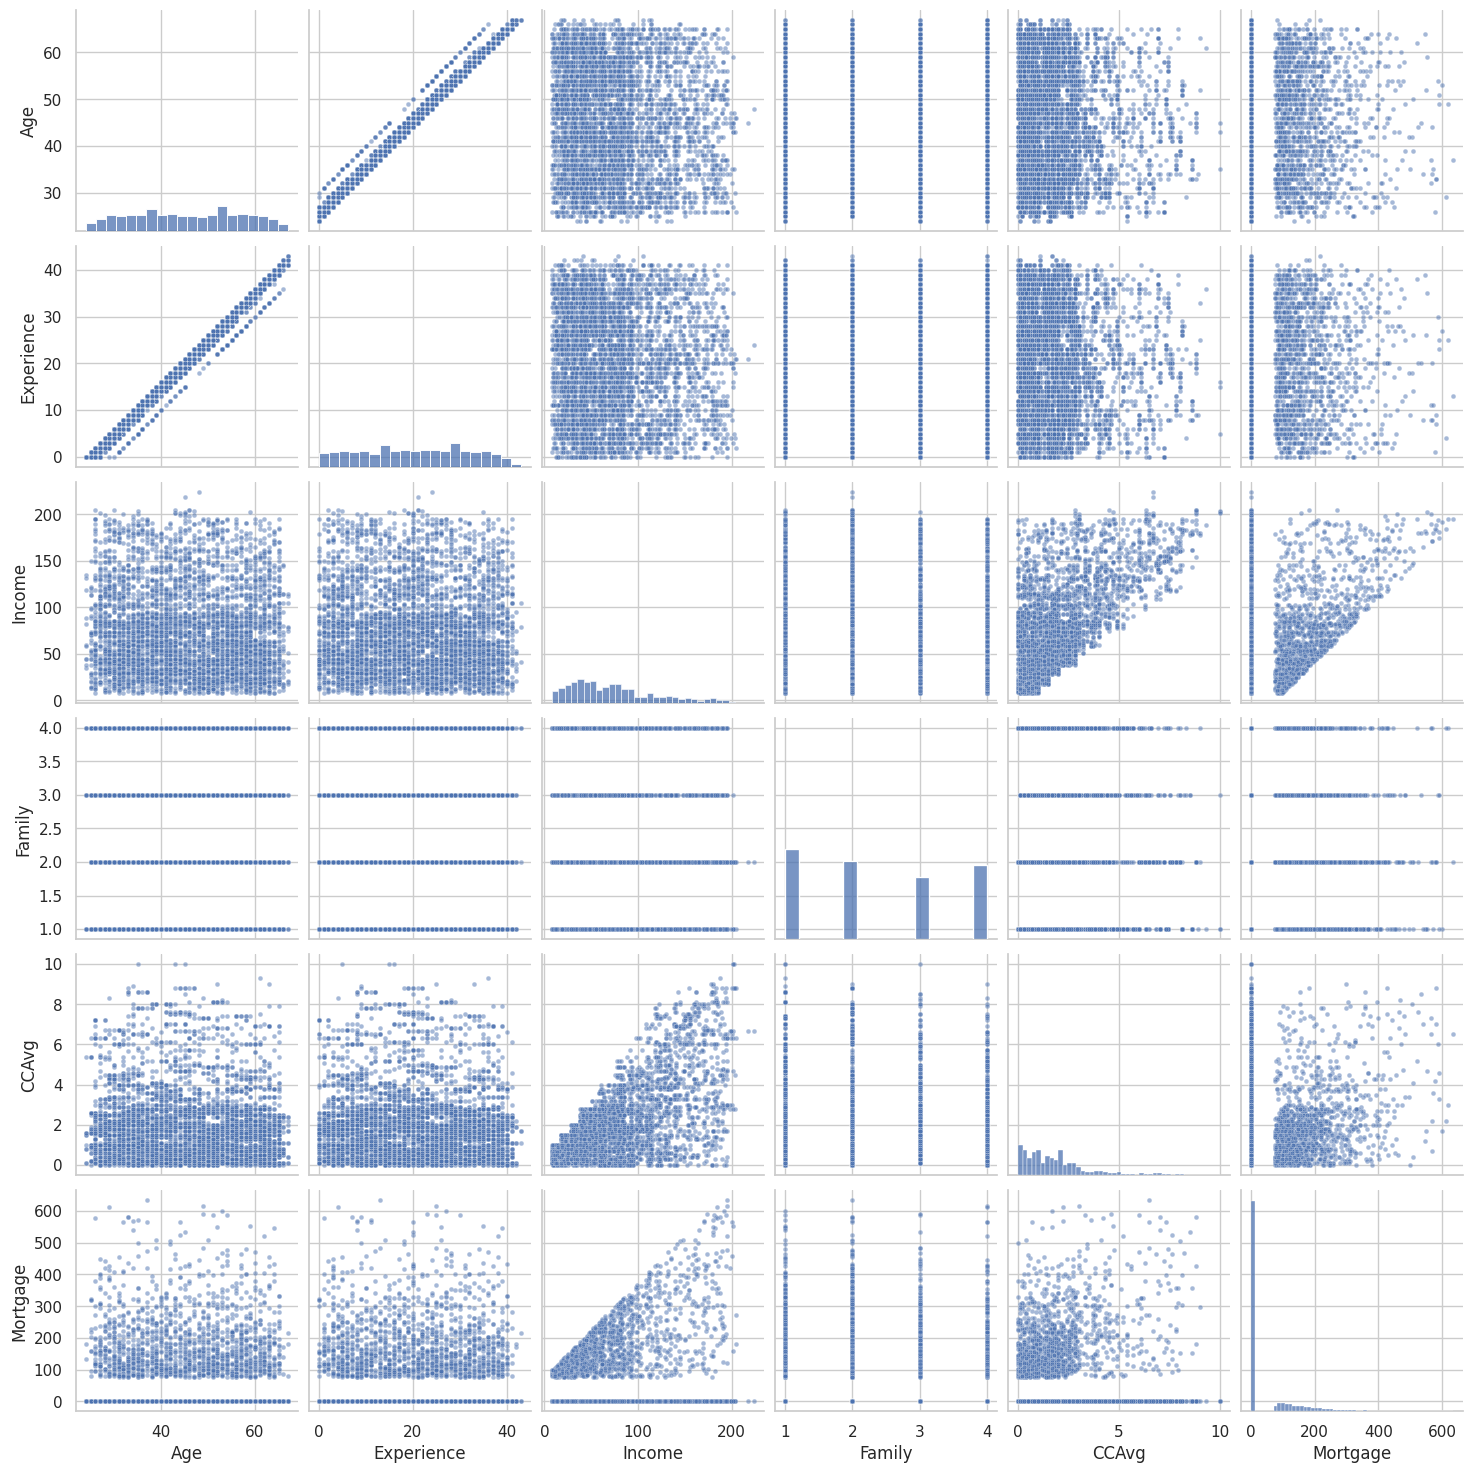

In [727]:
sns.pairplot(loan_df[num_cols], plot_kws={'s': 12, 'alpha': 0.5}, diag_kind='hist')
plt.show()

* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.

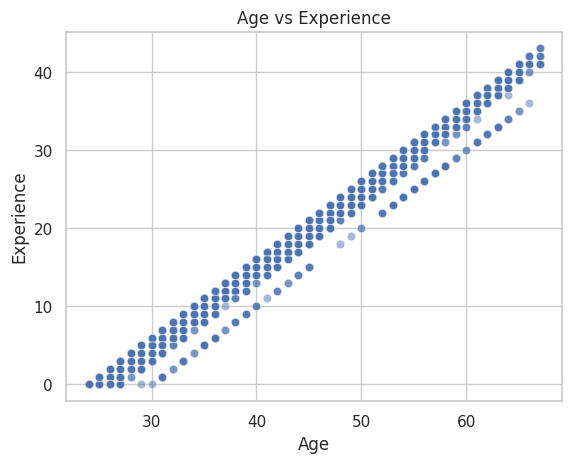

In [728]:
# Edad vs Experiencia
sns.scatterplot(x=loan_df['Age'], y=loan_df['Experience'], alpha=0.5)
plt.title('Age vs Experience')
plt.show()

Hay una relación directa casi una recta, esto quiere decir que a mayor edad hay más experiencia y viceversa. Esto es lógico porque conforme pasa más tiempo una persona tiene más edad y gana más experiencia

* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

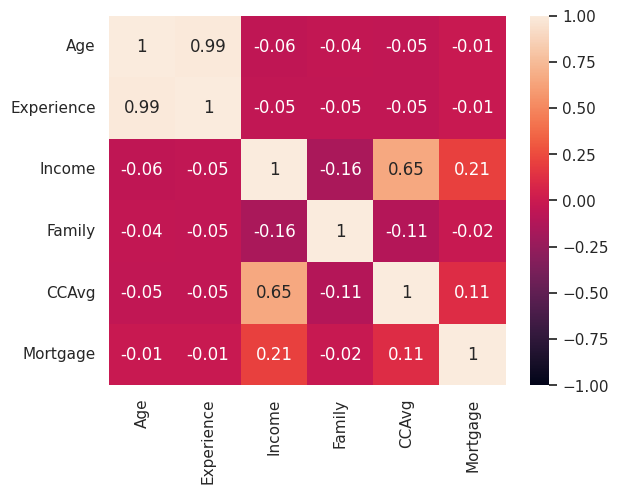

In [729]:
sns.heatmap(round(loan_df[num_cols].corr(numeric_only=True), 2),  annot=True,vmin=-1, vmax=1)
plt.show()



La correlación de Pearson entre Age y Experience es 0.99, esto nos quiere decir que hay una relación lineal, hace sentido al analisis anterior

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.

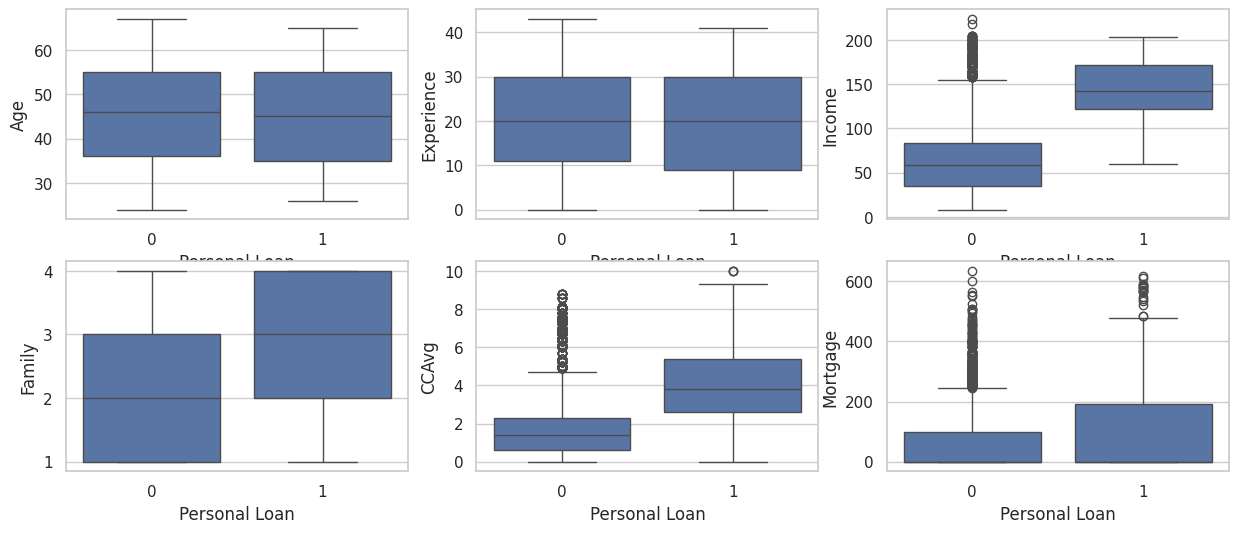

In [730]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
    sns.boxplot(x='Personal Loan', y=col, data=loan_df, ax=ax)

plt.show()

* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.

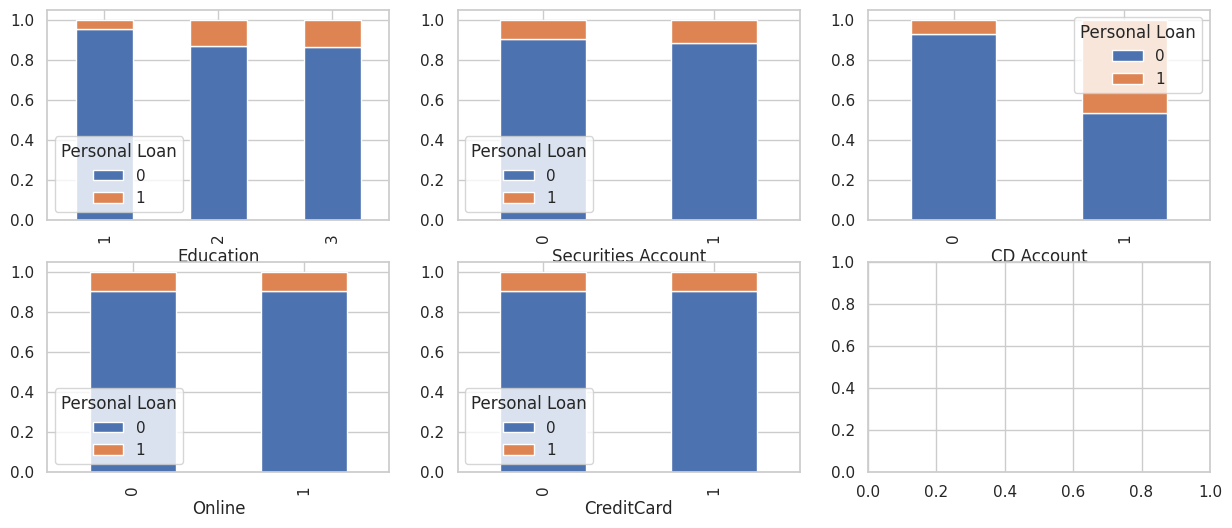

In [731]:
cat_vs_loan = ['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()

for col, ax in zip(cat_vs_loan, axes):
    pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index').plot(kind='bar', stacked=True, ax=ax)

plt.show()

* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


Income (numerica) es una variable que diferencia mucho a los grupos, las cajas no se cruzan practicamente, los que aceptaron el préstamo tienen una mediana de ingreso de aprox 150 mil contra unos 50 mil aprox de los que no aceptaron

CD Account (categorica) tiene el patrón más fuerte, el casi 50% de quienes tienen cuenta de CD acepto el préstamo contra solo el casi 10% de quienes no la tienen


**Declaración de uso de IA**



*   Anthropic. (2026). *Claude (Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para dar formato a los graficos y puedan encajar mejor uno al lado de otro. https://claude.ai/